# CALCE CS2 — Raw-cycle preprocessing, feature extraction & statistical selection

**Purpose:** inspect original Arbin/CALCE logs, create defensible per-cycle SOH labels, extract charging features, and rank features for **future-cycle SOH prediction**. The notebook does **not** assume that every CS2 workbook has identical sheets/columns. It logs missing fields and refuses to invent measurements. 

**Before running:** set `RAW_DIR` to the directory of your unzipped CS2 files. Start with one or two batteries. Original workbooks are not included in this notebook; **no raw CS2 workbook has been verified here**.

**Outputs:** `schema_inventory.csv`, `cs2_cycle_features.csv`, `cs2_quality_report.csv`, `cs2_pearson_spearman.csv`, `cs2_mutual_information.csv`, `cs2_redundancy_matrix.csv`, `cs2_selected_features.csv`, `feature_holdout_importance.csv`.

**Research controls:** battery-held-out validation; correlations on training cells only; avoid same-cycle discharge capacity as input; don't call unknown unrecorded intervals measured rest; no forward/back fills across cycles.

In [1]:
# Run once if dependencies are missing:
# %pip install pandas numpy scipy scikit-learn matplotlib openpyxl tqdm
from pathlib import Path
import re, warnings, json, hashlib
import numpy as np
import pandas as pd
from scipy.stats import pearsonr, spearmanr
from sklearn.feature_selection import mutual_info_regression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
from IPython.display import display
from tqdm.auto import tqdm
print('pandas',pd.__version__)


pandas 3.1.0


## 1 · Configure paths and measurement assumptions

**Important:** `SOH` is based on a *complete observed discharge* over the expected voltage window. A partial charge/discharge is not automatically a usable SOH label. `NOMINAL_AH=1.1` applies to standard CS2 cells; verify nominal capacity and protocol for any special series. Current polarity can be forced if automatic inference gets it wrong.

In [2]:
RAW_DIR = Path(r"C:\Projects\Battery_SOH_Diverse\CS2")
OUT_DIR = RAW_DIR / "cs2_processed"
OUT_DIR.mkdir(parents=True, exist_ok=True)
NOMINAL_AH = 1.10
CURRENT_SIGN = "auto"  # "auto", "positive_charge", "negative_charge"
MIN_ABS_CURRENT_A = 0.03
CC_TO_CV_V = 4.16  # operational heuristic only; CV detection also checks current decay
FULL_DISCHARGE_START_V = 4.00
FULL_DISCHARGE_END_V = 2.85
MIN_DISCHARGE_POINTS = 12
MIN_CHARGE_POINTS = 12
MIN_DISCHARGE_AH = 0.25
MAX_SAMPLE_INTERVAL_S = 600  # integration ignores discontinuities above this value
MAX_ROWS_PER_SHEET = None   # None = all rows, e.g. 10000 for exploratory debugging
# Optional explicit column overrides by semantic key. Supply original header strings when needed.
COLUMN_OVERRIDES = {
    # "cycle": "Cycle_Index", "current": "Current(A)", "voltage": "Voltage(V)",
    # "time": "Test_Time(s)", "datetime": "Date_Time", "step": "Step_Index",
    # "capacity": "Discharge_Capacity(Ah)",
}
# Exclude non-raw summary/statistics files from extraction. Still inventoried separately.
ACCEPT_EXTENSIONS = {".xlsx", ".xlsm", ".xls", ".csv"}
SEED = 42
print('Raw folder:', RAW_DIR)
print('Output folder:', OUT_DIR)


Raw folder: C:\Projects\Battery_SOH_Diverse\CS2
Output folder: C:\Projects\Battery_SOH_Diverse\CS2\cs2_processed


## 2 · Inventory all files and inspect sheets/headers

CALCE archives often contain channel files and separate statistics workbooks. Only sheets with time, voltage, current and cycle information are eligible for extraction. Review `schema_inventory.csv` if the detected columns look incorrect.

In [3]:
ALIASES = {
 'cycle':['cycle_index','cycle index','cycle','cycle number','cyc#','cyc'],
 'step':['step_index','step index','step','step number'],
 'time':['test_time(s)','test time(s)','test_time','test time','total_time','total time','time(s)','time_sec','time_seconds','testtime'],
 'datetime':['date_time','date time','datetime','timestamp','recorded time','time stamp'],
 'voltage':['voltage(v)','voltage','voltage_v','u(v)','voltage (v)'],
 'current':['current(a)','current','current_a','i(a)','current (a)'],
 'capacity':['discharge_capacity(ah)','discharge capacity(ah)','discharge_capacity','discharge capacity','dchg. cap.(ah)'],
 'charge_capacity':['charge_capacity(ah)','charge capacity(ah)','charge_capacity','charge capacity'],
 'temperature':['temperature(c)','temperature(°c)','temperature','temp(c)','temp'],
 'step_type':['step_type','step type','state','status','step name']
}
def norm_header(s): return re.sub(r'[^a-z0-9]+','',str(s).lower())
def detect_cols(columns):
    cols=list(columns); canon={norm_header(x):x for x in cols}; result={}
    for sem, candidates in ALIASES.items():
        if sem in COLUMN_OVERRIDES and COLUMN_OVERRIDES[sem] in cols:
            result[sem]=COLUMN_OVERRIDES[sem]; continue
        for alias in candidates:
            key=norm_header(alias)
            if key in canon: result[sem]=canon[key]; break
    return result

def battery_from_path(path):
    m=re.search(r'(CS2[_ -]?\d+)',str(path),flags=re.I)
    return 'CS2_'+re.search(r'\d+',m.group(1)).group(0) if m else path.parent.name.upper()

def probe_table(path, sheet, header_row=0):
    if path.suffix.lower()=='.csv':
        return pd.read_csv(path, nrows=8, header=header_row, low_memory=False)
    return pd.read_excel(path, sheet_name=sheet, nrows=8, header=header_row)

def file_inventory(root):
    records, sources = [], []
    paths = sorted(p for p in root.rglob('*') if p.is_file()
                   and p.suffix.lower() in ACCEPT_EXTENSIONS
                   and OUT_DIR not in p.parents and not p.name.startswith('~$'))
    for p in tqdm(paths, desc='Inventory'):
        battery = battery_from_path(p)
        try:
            sheets = ['CSV'] if p.suffix.lower()=='.csv' else pd.ExcelFile(p).sheet_names
            for sh in sheets:
                record = {'path':str(p), 'battery':battery, 'sheet':sh,
                          'eligible':False, 'header_row':None, 'columns':'',
                          'mapping':'{}', 'error':'', 'status':'missing_required_columns'}
                try:
                    preview = probe_table(p, sh)
                    mapping = detect_cols(preview.columns)
                    # Many laboratory exports have metadata before their real header.
                    if not (all(k in mapping for k in ('current','voltage','cycle'))
                            and ('time' in mapping or 'datetime' in mapping)):
                        best = (len(mapping), 0, preview, mapping)
                        for h in range(1, 16):
                            try:
                                candidate=probe_table(p,sh,header_row=h)
                                m=detect_cols(candidate.columns)
                                if len(m)>best[0]: best=(len(m),h,candidate,m)
                                if all(k in m for k in ('current','voltage','cycle')) and ('time' in m or 'datetime' in m):
                                    best=(len(m),h,candidate,m); break
                            except Exception: pass
                        _, header_row, preview, mapping = best
                    else:
                        header_row = 0
                    eligible = all(k in mapping for k in ('current','voltage','cycle')) and ('time' in mapping or 'datetime' in mapping)
                    record.update({'eligible':eligible, 'header_row':header_row,
                                   'columns':repr(list(preview.columns)),
                                   'mapping':json.dumps(mapping),
                                   'status':'eligible' if eligible else 'missing_required_columns'})
                    if eligible: sources.append((p,sh,mapping,header_row))
                except Exception as e:
                    record.update({'status':'read_error','error':str(e)[:300]})
                records.append(record)
        except Exception as e:
            records.append({'path':str(p), 'battery':battery, 'sheet':'',
                            'eligible':False, 'header_row':None, 'columns':'',
                            'mapping':'{}', 'error':str(e)[:300], 'status':'open_error'})
    return pd.DataFrame(records,columns=['path','battery','sheet','eligible','header_row','columns','mapping','error','status']),sources

inventory,sources=file_inventory(RAW_DIR)
inventory.to_csv(OUT_DIR/'schema_inventory.csv',index=False)
print('Files/sheets inventoried:',len(inventory),'| eligible raw sheets:',len(sources))
if len(inventory):
    print('Status counts:')
    display(inventory['status'].value_counts(dropna=False).to_frame('count'))
    display(inventory[['battery','path','sheet','header_row','eligible','columns','mapping','error']].head(20))
if not sources:
    print('NO ELIGIBLE SHEETS. Inspect schema_inventory.csv; verify RAW_DIR, raw-channel workbooks, header rows and column aliases.')
    if len(inventory):
        print('First 10 representative file/sheet diagnostics:')
        display(inventory[['path','sheet','columns','error']].head(10))
    raise RuntimeError('No raw cycling sheets recognized. Do not proceed with extraction until schema mapping is fixed.')


Inventory:   0%|          | 0/549 [00:00<?, ?it/s]

Files/sheets inventoried: 1246 | eligible raw sheets: 697
Status counts:


,count
status,
eligible,697
missing_required_columns,549


,battery,path,sheet,header_row,eligible,columns,mapping,error
0,CS2_2,C:\Projects\Battery_SOH_Diverse\CS2\CS2_24\CS2...,Info,3,False,"['Channel', 'Start_DateTime', 'Schedule_File_N...","{""capacity"": ""Discharge_Capacity(Ah)"", ""temper...",
1,CS2_2,C:\Projects\Battery_SOH_Diverse\CS2\CS2_24\CS2...,Channel_1-009,0,True,"['Data_Point', 'Test_Time(s)', 'Date_Time', 'S...","{""cycle"": ""Cycle_Index"", ""step"": ""Step_Index"",...",
2,CS2_2,C:\Projects\Battery_SOH_Diverse\CS2\CS2_24\CS2...,Info,3,False,"['Channel', 'Start_DateTime', 'Schedule_File_N...","{""capacity"": ""Discharge_Capacity(Ah)"", ""temper...",
3,CS2_2,C:\Projects\Battery_SOH_Diverse\CS2\CS2_24\CS2...,Channel_1-009,0,True,"['Data_Point', 'Test_Time(s)', 'Date_Time', 'S...","{""cycle"": ""Cycle_Index"", ""step"": ""Step_Index"",...",
4,CS2_2,C:\Projects\Battery_SOH_Diverse\CS2\CS2_24\CS2...,Info,3,False,"['Channel', 'Start_DateTime', 'Schedule_File_N...","{""capacity"": ""Discharge_Capacity(Ah)"", ""temper...",
5,CS2_2,C:\Projects\Battery_SOH_Diverse\CS2\CS2_24\CS2...,Channel_1-009,0,True,"['Data_Point', 'Test_Time(s)', 'Date_Time', 'S...","{""cycle"": ""Cycle_Index"", ""step"": ""Step_Index"",...",
6,CS2_2,C:\Projects\Battery_SOH_Diverse\CS2\CS2_24\CS2...,Info,3,False,"['Channel', 'Start_DateTime', 'Schedule_File_N...","{""capacity"": ""Discharge_Capacity(Ah)"", ""temper...",
7,CS2_2,C:\Projects\Battery_SOH_Diverse\CS2\CS2_24\CS2...,Channel_1-009,0,True,"['Data_Point', 'Test_Time(s)', 'Date_Time', 'S...","{""cycle"": ""Cycle_Index"", ""step"": ""Step_Index"",...",
8,CS2_2,C:\Projects\Battery_SOH_Diverse\CS2\CS2_24\CS2...,Info,3,False,"['Channel', 'Start_DateTime', 'Schedule_File_N...","{""capacity"": ""Discharge_Capacity(Ah)"", ""temper...",
9,CS2_2,C:\Projects\Battery_SOH_Diverse\CS2\CS2_24\CS2...,Channel_1-009,0,True,"['Data_Point', 'Test_Time(s)', 'Date_Time', 'S...","{""cycle"": ""Cycle_Index"", ""step"": ""Step_Index"",...",


## 3 · Normalize time, infer charge direction and extract cycle features

**Cycle labels** are inferred only from complete observed discharge segments and integrated current, never from future cycles. The voltage-span and continuity tests are deliberately conservative. **Check polarity and current/voltage charts manually before trusting the output.** Where step-level cycle index is reused or reset, files are tracked separately through `source_file` and `source_sheet`.

In [4]:
def as_seconds(df, mapping):
    if 'time' in mapping:
        s=df[mapping['time']]
        v=pd.to_numeric(s,errors='coerce')
        if v.notna().sum() > len(df)*0.6: return v.to_numpy(dtype=float)
        dt=pd.to_timedelta(s,errors='coerce')
        if dt.notna().sum()>len(df)*0.6:return dt.dt.total_seconds().to_numpy(dtype=float)
    if 'datetime' in mapping:
        dt=pd.to_datetime(df[mapping['datetime']],errors='coerce')
        if dt.notna().sum()>=2:return (dt-dt.dropna().iloc[0]).dt.total_seconds().to_numpy(dtype=float)
    return np.full(len(df),np.nan)

def infer_sign(cur,vol,t):
    if CURRENT_SIGN=='positive_charge':return 1
    if CURRENT_SIGN=='negative_charge':return -1
    dv=np.diff(vol); dt=np.diff(t); valid=np.isfinite(dv)&np.isfinite(dt)&(dt>0)&(dt<=MAX_SAMPLE_INTERVAL_S)
    valid &= np.isfinite(cur[1:])&(np.abs(cur[1:])>MIN_ABS_CURRENT_A)
    if valid.sum()<15:return 0
    z=np.sign(dv[valid])*np.sign(cur[1:][valid])
    z=z[z!=0]
    if len(z)<15:return 0
    alignment=float(np.mean(z))
    return 1 if alignment>0.08 else (-1 if alignment< -0.08 else 0)

def integrate_ah(t,i,valid=None):
    t=np.asarray(t,dtype=float);i=np.asarray(i,dtype=float)
    if len(t)<2:return np.nan
    dt=np.diff(t); ok=np.isfinite(dt)&(dt>0)&(dt<=MAX_SAMPLE_INTERVAL_S)&np.isfinite(i[:-1])&np.isfinite(i[1:])
    if valid is not None:ok &= np.asarray(valid[:-1])&np.asarray(valid[1:])
    return float(np.sum(0.5*(i[:-1][ok]+i[1:][ok])*dt[ok])/3600)

def window_cross_time(t,v,a,b,valid):
    # Avoid interpolating through absent measurements; only measure an observed crossing pair.
    def first_cross(target):
        ii=np.where(valid[:-1]&valid[1:]&(v[:-1]<=target)&(v[1:]>=target)&(v[1:]>v[:-1])&((np.diff(t)>0)&(np.diff(t)<=MAX_SAMPLE_INTERVAL_S)))[0]
        if not len(ii):return np.nan
        j=ii[0];return float(t[j]+(target-v[j])*(t[j+1]-t[j])/(v[j+1]-v[j]))
    aa,bb=first_cross(a),first_cross(b)
    return (bb-aa) if np.isfinite(aa) and np.isfinite(bb) and bb>aa else np.nan

def safe_float(a,fn=np.nanmean):
    a=np.asarray(a,dtype=float); a=a[np.isfinite(a)]
    return float(fn(a)) if len(a) else np.nan

def extract_cycle(g, mapping, polarity, path, sheet, cyc):
    g=g.copy();t=as_seconds(g,mapping);v=pd.to_numeric(g[mapping['voltage']],errors='coerce').to_numpy(float)
    ic=pd.to_numeric(g[mapping['current']],errors='coerce').to_numpy(float)
    if polarity==0:return None,{'reason':'ambiguous_polarity','source_file':str(path),'cycle':cyc}
    charge=polarity*ic
    ix=np.argsort(t,kind='stable'); t=t[ix];v=v[ix];charge=charge[ix];g=g.iloc[ix]
    ch=(charge>MIN_ABS_CURRENT_A)&np.isfinite(v);dis=(charge< -MIN_ABS_CURRENT_A)&np.isfinite(v)
    if not np.isfinite(t).all() or len(t)<5 or np.nanmax(t)-np.nanmin(t)<=0:
        return None,{'reason':'invalid_time','source_file':str(path),'cycle':cyc}
    # Step threshold for CV approximates transition to 4.2 V plateau and declining current.
    cv=ch&(v>=CC_TO_CV_V); cc=ch&~cv
    ccpts=int(cc.sum()); cvpts=int(cv.sum()); ndis=int(dis.sum())
    discharge_v=v[dis]; charge_v=v[ch]
    capacity=integrate_ah(t,np.maximum(-charge,0),dis)
    qcharge=integrate_ah(t,np.maximum(charge,0),ch)
    # 95th/5th percentile guards against single-sample voltage glitches.
    vdis_high=float(np.nanpercentile(discharge_v,95)) if ndis else np.nan
    vdis_low=float(np.nanpercentile(discharge_v,5)) if ndis else np.nan
    complete=(ndis>=MIN_DISCHARGE_POINTS and np.isfinite(capacity) and capacity>=MIN_DISCHARGE_AH
              and vdis_high>=FULL_DISCHARGE_START_V and vdis_low<=FULL_DISCHARGE_END_V)
    ch_t=t[ch];cc_t=t[cc];cv_t=t[cv]
    def dur(q):return float(np.max(q)-np.min(q)) if len(q)>1 else np.nan
    # IR estimate only for immediate measured current-switch samples, not unknown rest gaps.
    transition=[]
    for j in range(1,len(t)):
        if 0<t[j]-t[j-1]<=30 and abs(charge[j]-charge[j-1])>=0.2 and abs(charge[j]-charge[j-1])>0.05:
            transition.append(abs((v[j]-v[j-1])/(charge[j]-charge[j-1])))
    out={'battery':battery_from_path(path),'source_file':str(path),'source_sheet':sheet,'cycle_raw':str(cyc),
      'n_rows':len(g),'n_charge_points':int(ch.sum()),'n_discharge_points':ndis,
      'charge_duration_s':dur(ch_t),'cc_duration_s':dur(cc_t),'cv_duration_s':dur(cv_t),
      'charge_throughput_ah':qcharge,'cc_throughput_ah':integrate_ah(t,np.maximum(charge,0),cc),
      'cv_throughput_ah':integrate_ah(t,np.maximum(charge,0),cv),
      'cc_mean_current_a':safe_float(charge[cc]),'cv_mean_current_a':safe_float(charge[cv]),
      'cc_start_voltage':float(charge_v[0]) if len(charge_v) else np.nan,
      'charge_voltage_mean':safe_float(charge_v),
      'charge_voltage_std':safe_float(charge_v,np.std),
      'time_3p8_to_4p0_s':window_cross_time(t,v,3.8,4.0,ch),
      'time_3p9_to_4p1_s':window_cross_time(t,v,3.9,4.1,ch),
      'ir_step_proxy_ohm':safe_float(transition,np.median),
      'discharge_capacity_ah':capacity,'soh':capacity/NOMINAL_AH if complete else np.nan,
      'valid_full_discharge':bool(complete),'cc_present':bool(ccpts>=MIN_CHARGE_POINTS),
      'cv_present':bool(cvpts>=4),'charge_present':bool(ch.sum()>=MIN_CHARGE_POINTS),
      'polarity':polarity,'cycle_tstart_s':float(np.nanmin(t)),'cycle_tend_s':float(np.nanmax(t))}
    if 'temperature' in mapping:
        temp=pd.to_numeric(g[mapping['temperature']],errors='coerce').to_numpy(float)
        out['temp_mean_c']=safe_float(temp[ch]);out['temp_max_c']=safe_float(temp[ch],np.max)
    reason='pass' if complete and out['charge_present'] else ('no_complete_discharge' if not complete else 'no_charge')
    return out,{'reason':reason,'source_file':str(path),'source_sheet':sheet,'battery':battery_from_path(path),'cycle':str(cyc),'n_rows':len(g)}


### Processing caution

The first-pass `cv_duration_s` is a **voltage-threshold proxy**, not a verified step-identified CV duration. Its reliability should be checked against actual Arbin step IDs and current decay. ICA and DVA are **not fabricated** from under-sampled logs; add them only after inspecting raw charge curves and validating smooth derivative extraction.

In [5]:
all_rows=[];all_q=[]
for p,sh,mapping,header_row in tqdm(sources,desc='Read eligible sheets'):
    try:
        if p.suffix.lower()=='.csv': d=pd.read_csv(p,nrows=MAX_ROWS_PER_SHEET,header=header_row,low_memory=False)
        else: d=pd.read_excel(p,sheet_name=sh,nrows=MAX_ROWS_PER_SHEET,header=header_row)
        cyc_col=mapping['cycle'];d=d[d[cyc_col].notna()]
        if d.empty:continue
        # Prefer source-wide polarity; the same sign convention should apply to all cycles in a file.
        ti=as_seconds(d,mapping); vv=pd.to_numeric(d[mapping['voltage']],errors='coerce').to_numpy(float)
        ii=pd.to_numeric(d[mapping['current']],errors='coerce').to_numpy(float)
        polarity=infer_sign(ii,vv,ti)
        if polarity==0 and CURRENT_SIGN=='auto':
            all_q.append({'source_file':str(p),'source_sheet':sh,'reason':'ambiguous_polarity_file','battery':battery_from_path(p)})
            continue
        for cyc,g in d.groupby(cyc_col,sort=False,dropna=True):
            try:
                r,q=extract_cycle(g,mapping,polarity,p,sh,cyc)
                if r is not None: all_rows.append(r)
                all_q.append(q)
            except Exception as e: all_q.append({'source_file':str(p),'source_sheet':sh,'cycle':str(cyc),'reason':'exception: '+str(e)[:160]})
    except Exception as e:all_q.append({'source_file':str(p),'source_sheet':sh,'reason':'file_error: '+str(e)[:160]})
features=pd.DataFrame(all_rows);quality=pd.DataFrame(all_q)
if not features.empty:
    # Sort within battery by workbook filename and raw cycle index (fallback stable order).
    features['cycle_numeric']=pd.to_numeric(features['cycle_raw'],errors='coerce')
    features=features.sort_values(['battery','source_file','source_sheet','cycle_numeric','cycle_raw'],kind='stable').reset_index(drop=True)
    features['cycle_ordinal_in_export']=features.groupby('battery').cumcount()+1
features.to_csv(OUT_DIR/'cs2_cycle_features.csv',index=False)
quality.to_csv(OUT_DIR/'cs2_quality_report.csv',index=False)
print('Rows:',len(features),'| SOH-labeled cycles:',int(features.soh.notna().sum()) if 'soh' in features else 0)
if len(quality):display(quality.reason.value_counts(dropna=False).to_frame('count'))
if len(features):display(features.groupby('battery').agg(rows=('battery','size'),labeled=('soh','count'),mean_soh=('soh','mean')))


Read eligible sheets:   0%|          | 0/697 [00:00<?, ?it/s]

Rows: 32821 | SOH-labeled cycles: 64


,count
reason,
no_complete_discharge,32757
ambiguous_polarity_file,129
pass,64
invalid_time,14


,rows,labeled,mean_soh
battery,,,
CS2_2,32821,64,0.352466


## 4 · Quality audit and visual checks

Inspect a few original charge/discharge curves manually before selecting features. **Automated labeling may be wrong when files use nonstandard cycle indices, split steps, or timestamps reset within a workbook.** For split-cycle workbooks, reconstruct cycles across file boundaries before using SOH labels.

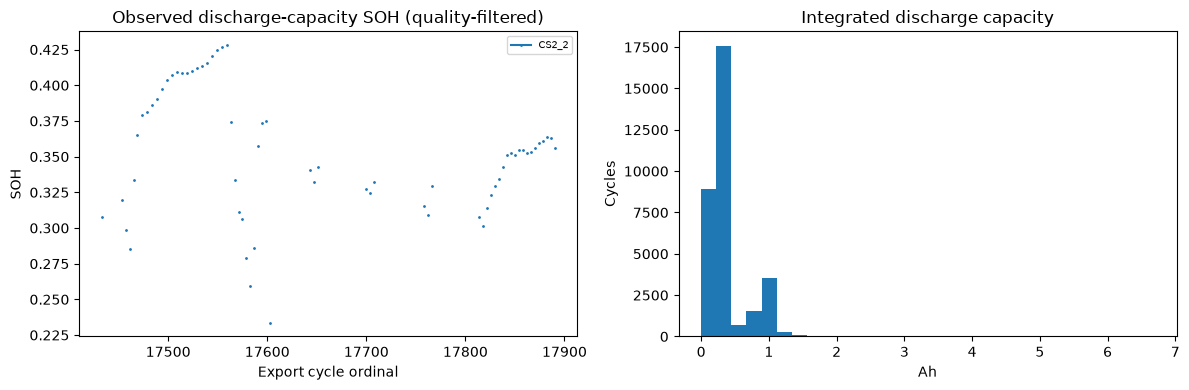

Out-of-range labeled SOH (>1.1 or <0.45): 64


In [6]:
if not features.empty:
    fig,axs=plt.subplots(1,2,figsize=(12,4))
    for battery,g in features.groupby('battery'):
        axs[0].plot(g['cycle_ordinal_in_export'],g['soh'],'.-',ms=2,label=battery)
    axs[0].set(title='Observed discharge-capacity SOH (quality-filtered)',xlabel='Export cycle ordinal',ylabel='SOH');axs[0].legend(fontsize=7)
    axs[1].hist(features['discharge_capacity_ah'].dropna(),bins=30)
    axs[1].set(title='Integrated discharge capacity',xlabel='Ah',ylabel='Cycles')
    plt.tight_layout();plt.savefig(OUT_DIR/'cs2_quality_overview.png',dpi=170);plt.show()
    print('Out-of-range labeled SOH (>1.1 or <0.45):',int(((features.soh>1.1)|(features.soh<0.45)).sum()))


## 5 · Battery-held-out split and eligible features

The statistics below are calculated **only on training batteries**. For actual multi-cycle forecasting, feature availability must be established at the forecast origin; these cycle-level fields should be aligned to the previous observed cycle and not the future target cycle. The column `cycle_ordinal_in_export` is an ordering aid only, not a verified physical cycle count.

In [7]:
# Set explicitly for a publication experiment. By default, reserve the last battery alphabetically.
HOLDOUT_BATTERY = None  # e.g. 'CS2_38'
ID_COLS={'battery','source_file','source_sheet','cycle_raw','cycle_numeric','cycle_ordinal_in_export',
         'cycle_tstart_s','cycle_tend_s','soh','discharge_capacity_ah','polarity','n_rows',
         'n_discharge_points','n_charge_points','valid_full_discharge','charge_present',
         'cc_present','cv_present'}
if len(features):
    bats=sorted(features.battery.unique());hold=HOLDOUT_BATTERY or (bats[-1] if len(bats)>1 else None)
    train=features[features.battery!=hold].copy() if hold else features.copy()
    holdout=features[features.battery==hold].copy() if hold else pd.DataFrame()
    train=train[train.soh.notna()];holdout=holdout[holdout.soh.notna()] if len(holdout) else holdout
    candidates=[c for c in train.select_dtypes(include='number').columns if c not in ID_COLS and not c.startswith('soh')]
    candidates=[c for c in candidates if train[c].notna().sum()>=max(15,int(0.3*len(train))) and train[c].nunique(dropna=True)>4]
    print('Training batteries:',sorted(train.battery.unique()),'| holdout:',hold,'| features:',candidates)
else:train=pd.DataFrame();holdout=pd.DataFrame();candidates=[]


Training batteries: ['CS2_2'] | holdout: None | features: ['charge_duration_s', 'cc_duration_s', 'cv_duration_s', 'charge_throughput_ah', 'cc_throughput_ah', 'cv_throughput_ah', 'cc_mean_current_a', 'cv_mean_current_a', 'cc_start_voltage', 'charge_voltage_mean', 'charge_voltage_std', 'time_3p9_to_4p1_s', 'ir_step_proxy_ohm']


## 6 · Per-cell Pearson/Spearman, pooled correlations, mutual information

Pooled correlation often looks impressive because both capacity and charging characteristics drift with cycle age. **Look for per-cell agreement and incremental predictive value** rather than simply sorting by absolute Pearson. Report correlation only when there are enough distinct, paired observations.

In [8]:
corr_rows=[];mi_rows=[]
if len(train):
    subsets=[('train_pooled',train)]+[(bat,g) for bat,g in train.groupby('battery')]
    for label,group in subsets:
        for col in candidates:
            sub=group[[col,'soh']].replace([np.inf,-np.inf],np.nan).dropna()
            if len(sub)<12 or sub[col].nunique()<4:continue
            pr=pearsonr(sub[col],sub.soh); sr=spearmanr(sub[col],sub.soh)
            corr_rows.append({'group':label,'feature':col,'n':len(sub),'pearson':pr.statistic,'pearson_p':pr.pvalue,'spearman':sr.statistic,'spearman_p':sr.pvalue})
            if label=='train_pooled' and len(sub)>=25:
                try:
                    mi=mutual_info_regression(sub[[col]],sub.soh,random_state=SEED,n_neighbors=5)[0]
                    mi_rows.append({'feature':col,'mutual_information':mi,'n':len(sub)})
                except Exception:pass
corr=pd.DataFrame(corr_rows);mi=pd.DataFrame(mi_rows)
corr.to_csv(OUT_DIR/'cs2_pearson_spearman.csv',index=False)
mi.to_csv(OUT_DIR/'cs2_mutual_information.csv',index=False)
if len(corr):display(corr[corr.group=='train_pooled'].assign(abs_spearman=lambda x:x.spearman.abs()).sort_values('abs_spearman',ascending=False).head(30))


,group,feature,n,pearson,pearson_p,spearman,spearman_p,abs_spearman
3,train_pooled,charge_throughput_ah,64,0.985347,2.438686e-49,0.987683,1.157327e-51,0.987683
8,train_pooled,cc_start_voltage,64,-0.683785,4.742294e-10,-0.979223,1.119708e-44,0.979223
11,train_pooled,time_3p9_to_4p1_s,49,0.978172,1.004513e-33,0.971837,3.736683e-31,0.971837
1,train_pooled,cc_duration_s,64,0.963750,2.778675e-37,0.965980,4.011552e-38,0.965980
4,train_pooled,cc_throughput_ah,64,0.963728,2.829659e-37,0.962179,1.010753e-36,0.962179
10,train_pooled,charge_voltage_std,64,0.949195,7.843242e-33,0.961035,2.504513e-36,0.961035
5,train_pooled,cv_throughput_ah,64,0.934245,1.862757e-29,0.934661,1.539665e-29,0.934661
9,train_pooled,charge_voltage_mean,64,-0.907203,5.378924e-25,-0.901969,2.721762e-24,0.901969
12,train_pooled,ir_step_proxy_ohm,64,-0.783146,2.060308e-14,-0.840659,3.655110e-18,0.840659
0,train_pooled,charge_duration_s,64,0.715377,3.095487e-11,0.698352,1.407469e-10,0.698352


## 7 · Redundancy, per-battery stability and greedy mRMR-style ranking

This is a **heuristic** relevance–redundancy score, not an optimized implementation of a published mRMR estimator. Pearson/Spearman rankings are observational, not causal. No feature selection may access the held-out battery.

In [9]:
selected_rows=[]
if len(train) and candidates:
    redundancy=train[candidates].corr(method='spearman').abs()
    redundancy.to_csv(OUT_DIR/'cs2_redundancy_matrix.csv')
    pool=corr[corr.group=='train_pooled'].set_index('feature')
    cellcorr=corr[corr.group!='train_pooled']
    score={}
    for col in candidates:
        if col not in pool.index:continue
        individual=cellcorr[cellcorr.feature==col].spearman.dropna()
        consensus=float(np.mean(np.sign(individual)==np.sign(pool.loc[col,'spearman']))) if len(individual) else 0
        stability=float(np.median(np.abs(individual))) if len(individual) else 0
        missing=float(train[col].isna().mean())
        score[col]=0.45*abs(float(pool.loc[col,'spearman']))+0.35*stability+0.20*consensus-0.25*missing
    remaining=list(score);chosen=[]
    while remaining:
        nxt=max(remaining,key=lambda c:score[c]-(0.45*max((redundancy.loc[c,s] if pd.notna(redundancy.loc[c,s]) else 0) for s in chosen) if chosen else 0))
        max_red=max([float(redundancy.loc[nxt,s]) for s in chosen if pd.notna(redundancy.loc[nxt,s])],default=0)
        selected_rows.append({'rank':len(chosen)+1,'feature':nxt,'base_score':score[nxt],'max_redundancy_to_selected':max_red,
                              'selection_score':score[nxt]-0.45*max_red,'missing_fraction':float(train[nxt].isna().mean())})
        chosen.append(nxt);remaining.remove(nxt)
selected=pd.DataFrame(selected_rows);selected.to_csv(OUT_DIR/'cs2_selected_features.csv',index=False)
if not (OUT_DIR/'cs2_redundancy_matrix.csv').exists():
    pd.DataFrame().to_csv(OUT_DIR/'cs2_redundancy_matrix.csv',index=False)
if len(selected):display(selected.head(20))


,rank,feature,base_score,max_redundancy_to_selected,selection_score,missing_fraction
0,1,charge_throughput_ah,0.990147,0.000000,0.990147,0.000000
1,2,cc_start_voltage,0.983379,0.974667,0.544778,0.000000
2,3,charge_voltage_std,0.968828,0.964606,0.534755,0.000000
3,4,cc_duration_s,0.972784,0.979991,0.531788,0.000000
4,5,cc_throughput_ah,0.969744,0.993773,0.522546,0.000000
5,6,cv_throughput_ah,0.947729,0.947079,0.521543,0.000000
6,7,charge_voltage_mean,0.921575,0.972390,0.484000,0.000000
7,8,time_3p9_to_4p1_s,0.918876,0.983571,0.476268,0.234375
8,9,ir_step_proxy_ohm,0.872527,0.931410,0.453393,0.000000
9,10,charge_duration_s,0.758681,0.855952,0.373503,0.000000


## 8 · Held-out predictive utility and permutation importance

This section evaluates **current-cycle association**, not future-cycle forecasting. It is a screening sanity check only; use windowed next-cycle prediction with strict time alignment for your final AIDO-SOH experiments. A holdout with one cell cannot establish cross-battery generalization. For proper feature choice, tune within training-side battery folds and use the held-out cell once for reporting.

In [10]:
importance=pd.DataFrame()
if len(holdout)>=25 and len(train)>=40 and candidates:
    cols=list(selected.feature.head(min(12,len(selected))))
    X=train[cols].replace([np.inf,-np.inf],np.nan); y=train.soh
    Xh=holdout[cols].replace([np.inf,-np.inf],np.nan);yh=holdout.soh
    # Trees support nan, but use a consistent imputation scheme for transparent deployment.
    mdl=make_pipeline(SimpleImputer(strategy='median',add_indicator=False),HistGradientBoostingRegressor(max_iter=120,max_leaf_nodes=7,l2_regularization=1.0,random_state=SEED))
    mdl.fit(X,y);pred=mdl.predict(Xh)
    print('HOLDOUT cell:',hold,'| current-cycle RMSE:',round(float(np.sqrt(mean_squared_error(yh,pred))),5),'MAE:',round(float(mean_absolute_error(yh,pred)),5))
    perm=permutation_importance(mdl,Xh,yh,scoring='neg_root_mean_squared_error',n_repeats=6,random_state=SEED)
    importance=pd.DataFrame({'feature':cols,'rmse_increase_mean':perm.importances_mean,'rmse_increase_std':perm.importances_std}).sort_values('rmse_increase_mean',ascending=False)
    display(importance)
else:print('Not enough battery-disjoint labeled data for a held-out diagnostic; skipping.')
importance.to_csv(OUT_DIR/'feature_holdout_importance.csv',index=False)


Not enough battery-disjoint labeled data for a held-out diagnostic; skipping.


## 9 · Export final manifest and research next steps

Before publishing: inspect raw voltage/current charts for each protocol; verify whether “complete discharge” thresholds fit every CS2 cell; handle files that split a physical cycle across workbooks; confirm feature validity and charge-direction inference. **ICA/DVA extraction and acquisition-curve truncation should be added only after a real original CS2 file is inspected.**

For AIDO-SOH, prepare two separate experiments: (a) masked **cycle-feature** consistency, using these CSV features; (b) physically valid **partial raw-curve** consistency, using full waveform measurements. Do not present (a) as evidence for (b).

In [11]:
manifest={'raw_dir':str(RAW_DIR),'nominal_capacity_ah':NOMINAL_AH,'battery_holdout':HOLDOUT_BATTERY,
          'heldout_actual':hold if len(features) else None,'batteries':sorted(features.battery.unique().tolist()) if len(features) else [],
          'feature_candidates':candidates,'features_ranked':selected.feature.tolist() if len(selected) else [],
          'notes':['CV time is heuristic; not verified step-based CC/CV segmentation',
                   'SOH labels require manual discharge-completeness validation',
                   'No ICA/DVA calculated without validated raw curves',
                   'Filewise export ordinal is not confirmed absolute cycle number',
                   'Feature selection uses training batteries only']}
(OUT_DIR/'cs2_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('Outputs:',OUT_DIR)
for f in sorted(OUT_DIR.iterdir()): print(' -',f.name)


Outputs: C:\Projects\Battery_SOH_Diverse\CS2\cs2_processed
 - cs2_cycle_features.csv
 - cs2_manifest.json
 - cs2_mutual_information.csv
 - cs2_pearson_spearman.csv
 - cs2_quality_overview.png
 - cs2_quality_report.csv
 - cs2_redundancy_matrix.csv
 - cs2_selected_features.csv
 - feature_holdout_importance.csv
 - schema_inventory.csv
